# Module 3a: audio path on dev
WER, critical-value errors, Experiment 2, attribution, gate threshold. Dev only. Run `python -m readback_guard.batch dev` in a Terminal first.

In [1]:
import pandas as pd
from readback_guard.config import ROOT, load_config
from readback_guard.asr import load_asr_cases, wer_table, critical_values
from readback_guard.evaluate import load_cases, rates, log_result, attribution, mcnemar
from readback_guard.score import run_cases, sweep, pick_threshold

cfg = load_config()
dev_asr = load_asr_cases(cfg, "dev")
dev_asr[["case_id", "atco_ref", "atco_text", "pilot_ref", "pilot_text"]].head()

,case_id,atco_ref,atco_text,pilot_ref,pilot_text
0,p0135,hotel zulu mike sierra four runway three one c...,hotel zulu mike sierra four runway three one c...,takeoff,takeoff
1,p0749,csa five three six runway one three cleared fo...,csa five three six runway one three cleared fo...,go runway one three csa five three si,runway one three csf five three six
2,p0048,jobair zero six two runway one three cleared t...,jober zero six two runway one three cleared to...,runway one three cleared to land juliett zulu,hello niagara three two two andrew hello
3,p0121,quality nine one romeo vacate via papa contact...,qutin nine one roma vicky two papa contact to ...,papa ground one one nine quality nine one rome...,stop burn ground one two three one nine qantas...
4,p0114,lux air five four eight two runway three one c...,luxor five four eight two runway three one cle...,clear takeoff three one thank you bye,cleared takeoff three one thank you bye bye


## 1. WER and critical-value error rate

In [2]:
wer_table(dev_asr)

{'atco': 0.179, 'pilot': 0.435, 'all': 0.272}

In [3]:
cv = critical_values(dev_asr)
print("critical-value error rate:", round(1 - cv.asr_ok.mean(), 3), "of", len(cv), "values")
cv.groupby(["side", "type"]).asr_ok.agg(["size", "mean"]).round(2)

critical-value error rate: 0.147 of 177 values


size  mean
side  type                 
atco  callsign     49  0.88
      frequency     4  0.75
      runway       40  1.00
      speed         3  1.00
      squawk        1  1.00
pilot callsign     41  0.78
      frequency     3  0.33
      runway       33  0.76
      speed         2  1.00
      squawk        1  1.00

## 2. Experiment 2: the same real pairs on human text and on Whisper text

In [4]:
dev_real = load_cases(cfg, "dev").query("kind == 'real'")
human = run_cases(dev_real, cfg)
asr = run_cases(dev_asr, cfg)
pd.DataFrame({"human text": rates(human), "Whisper text": rates(asr)})

,human text,Whisper text
n_errors,15,15
detected,13,13
detection_rate,0.867,0.867
detection_ci,"(0.621, 0.963)","(0.621, 0.963)"
n_correct,37,37
false_alarms,2,23
false_alarm_rate,0.054,0.622
false_alarm_ci,"(0.015, 0.177)","(0.461, 0.759)"
exact_verdict_rate,0.865,0.404
say_again,0,0


In [5]:
m, table = attribution(human, asr)
print(mcnemar(m))
table

{'human_only_right': 23, 'asr_only_right': 2, 'p_value': 0.0}


cause,language understanding,right on both,right only on Whisper text,speech recognition,total
gold,,,,,
correct readback (false alarm if wrong),2,14,0,21,37
real error (miss if wrong),0,11,2,2,15
total,2,25,2,23,52


In [6]:
cols = ["case_id", "verdict", "pred_human", "pred_asr", "cause"]
look = m[m.cause != "right on both"][cols].merge(asr[["case_id", "pilot_ref", "pilot_text", "reason"]], on="case_id")
look

,case_id,verdict,pred_human,pred_asr,cause,pilot_ref,pilot_text,reason
0,p0749,CORRECT,WRONG_CALLSIGN,WRONG_CALLSIGN,language understanding,go runway one three csa five three si,runway one three csf five three six,callsign csa 536 read back as csf536
1,p0365,CORRECT,CORRECT,WRONG_VALUE,speech recognition,and one two one decimal nine csa five papa cha...,one two one the two nine csa five papa charlie...,frequency 121.9 read back as 121.29
2,p0487,CORRECT,CORRECT,WRONG_CALLSIGN,speech recognition,runway one three clear to land csa two delta lima,runway one three cleared to land csa two dot t...,callsign sydurata lima read back as csa 2.31
3,p0096,CORRECT,CORRECT,WRONG_CALLSIGN,speech recognition,clear takeoff runway three one cs,equity takeoff runway c one six eight,callsign csa 72c read back as equity
4,p0447,CORRECT,CORRECT,WRONG_VALUE,speech recognition,speed one sixty till four miles fi csa eight t...,speed one six two four miles five csa to sign,speed 160 read back as 162
5,p0257,CORRECT,CORRECT,WRONG_CALLSIGN,speech recognition,reducing below one fifty csa seven alfa jul,reducing below one fifty csa seven off a two,callsign alfa juliett read back as csa7
6,p0428,CORRECT,CORRECT,WRONG_CALLSIGN,speech recognition,line up one three austrian seven one two zulu,lineup one three astro seven one two zero,callsign student 712z read back as astro 7120
7,p0110,CORRECT,CORRECT,WRONG_CALLSIGN,speech recognition,runway three one cleared to land cimber three ...,runway three one cleared to land qimbo three f...,callsign kimber 3523 read back as qimbo 3523
8,p0699,CORRECT,CORRECT,WRONG_VALUE,speech recognition,lufthansa four tango papa clear to land one three,four tango papa cleared to land four three,runway 13 read back as 43
9,p0098,CORRECT,CORRECT,WRONG_CALLSIGN,speech recognition,line up and cleared for takeoff runway three o...,line up and contact over runway three line up ...,callsign skytravel 1102 read back as redrail 1102


In [7]:
log_result("exp2_human_real", "dev", "ref", rates(human), cfg, notes="real pairs only, prompt v1")
log_result("exp2_whisper", "dev", "asr", rates(asr), cfg, notes="real pairs only, prompt v1, no gate")

## 3. The gate: threshold curve on dev

In [ ]:
from readback_guard.score import pick_threshold_youden
print("first rule (Youden) would pick:", pick_threshold_youden(curve))
best = pick_threshold(curve, cfg["gate"]["max_say_again"])

picked threshold: 0.0


,threshold,detection_rate,false_alarm_rate,say_again_rate,youden
0,0.00,0.867,0.622,0.000,0.245
1,0.10,0.867,0.649,0.019,0.218
2,0.20,0.867,0.676,0.096,0.191
3,0.30,0.867,0.676,0.173,0.191
4,0.40,0.867,0.676,0.192,0.191
5,0.50,0.867,0.703,0.250,0.164
6,0.60,0.867,0.784,0.423,0.083
7,0.70,0.933,0.838,0.577,0.095
8,0.80,0.933,0.865,0.673,0.068
9,0.90,0.933,0.892,0.731,0.041


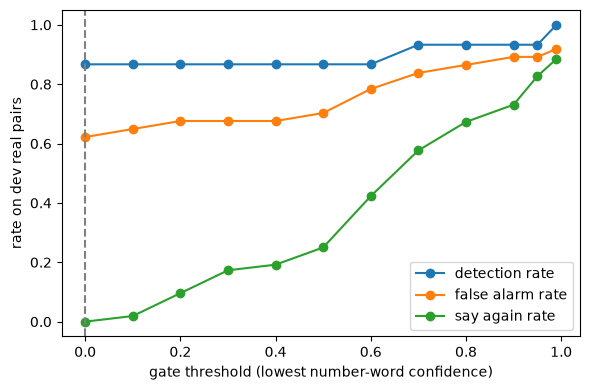

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
for col in ["detection_rate", "false_alarm_rate", "say_again_rate"]:
    ax.plot(curve.threshold, curve[col], marker="o", label=col.replace("_", " "))
ax.axvline(best, color="grey", linestyle="--")
ax.set_xlabel("gate threshold (lowest number-word confidence)")
ax.set_ylabel("rate on dev real pairs")
ax.legend()
fig.tight_layout()
fig.savefig(ROOT / "results" / "figures" / "gate_curve_dev.png", dpi=150)

In [10]:
gated = run_cases(dev_asr, cfg, best)
log_result("exp3_whisper_gate", "dev", "asr", rates(gated), cfg, notes=f"gate threshold {best}")
gated[gated.pred == "SAY_AGAIN"][["case_id", "verdict", "reason", "pilot_text"]]

,case_id,verdict,reason,pilot_text


Now put the picked threshold into `configs/default.yaml` (`gate.threshold`) and commit. From then on it is frozen.